# Deep Q-Network no Lunar Lander

Vinicius Trindade Dias Abel - 2020007112

## Introdução

Este trabalho aborda o problema **```Lunar Lander```**, disponibilizado pela biblioteca Gymnasium. O objetivo do ambiente é controlar os motores de uma nave espacial para realizar um pouso suave em uma zona delimitada na superfície lunar, lidando com a física de gravidade e inércia.

O ambiente apresenta as seguintes características principais:
-	**Espaço de Estados:** Contínuo, composto por um vetor de 8 dimensões que inclui coordenadas (x, y), velocidades lineares, ângulo, velocidade angular e indicadores de contato das pernas com o solo.
-  	**Espaço de Ações:** Discreto, com 4 opções de controle: não fazer nada, acionar o motor principal, acionar o motor esquerdo ou acionar o motor direito.
-	**Recompensa:** Baseada na proximidade do alvo, suavidade do pouso e economia de combustível (penalidade por uso dos motores).

A solução proposta consiste na implementação do algoritmo **```Deep Q-Network (DQN)```**. Esta técnica estende o algoritmo Q-Learning tradicional utilizando Redes Neurais Profundas como aproximadores de função para estimar os valores Q(s, a), permitindo lidar eficientemente com o espaço de estados contínuo do problema.

O desenvolvimento do trabalho foi estruturado nas seguintes etapas:
-	Implementação manual do agente DQN utilizando a biblioteca PyTorch, incorporando mecanismos de Experience Replay e Target Networks com atualização periódica para estabilidade do aprendizado.
-	Realização de uma busca sistemática de hiperparâmetros para identificar a configuração que maximiza o retorno médio e a estabilidade do agente.
-	Análise comparativa de desempenho entre a solução implementada e a versão de referência da biblioteca Stable Baselines3 (SB3).


## Deep Q-Network

### Configurações Iniciais

In [19]:
# --- Imports para instalação e configuração inicial ---
import sys
from importlib import metadata
import os

In [20]:
# --- Instalação de pacotes ---
!pip install --upgrade pip setuptools wheel
!pip install box2d
!pip install swig
!pip install gymnasium 
!pip install pygame
!pip install numpy matplotlib pandas tqdm torch torchvision stable-baselines3

In [21]:
# --- Imports principais ---
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt
import pandas as pd
import time
import itertools
import pickle
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.callbacks import CallbackList
from stable_baselines3.common.callbacks import StopTrainingOnMaxEpisodes

In [22]:
# --- Checagem de versões ---
def version_str(pkg_name):
    try:
        return metadata.version(pkg_name)
    except Exception:
        return "n/a"

print("Versões instaladas:")
print(f" Python...........: {sys.version.splitlines()[0]}")
print(f" numpy............: {version_str('numpy')}")
print(f" torch............: {torch.__version__}")
print(f" gymnasium........: {version_str('gymnasium')}")
print(f" box2d............: {version_str('box2d')}")
print(f" pygame...........: {version_str('pygame')}")
print(f" stable-baselines3: {version_str('stable-baselines3')}")
print(f" matplotlib.......: {version_str('matplotlib')}")
print(f" pandas...........: {version_str('pandas')}")
print(f" tqdm.............: {version_str('tqdm')}")
print(f" pygame.............: {version_str('pygame')}")
print(f" swig.............: {version_str('swig')}")
print(f" box2d.............: {version_str('box2d')}")

Versões instaladas:
 Python...........: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
 numpy............: 1.26.4
 torch............: 2.8.0+cu129
 gymnasium........: 1.2.1
 box2d............: 2.3.10
 pygame...........: 2.6.1
 stable-baselines3: 2.7.0
 matplotlib.......: 3.8.2
 pandas...........: 2.2.2
 tqdm.............: 4.67.1
 pygame.............: 2.6.1
 swig.............: 4.4.0
 box2d.............: 2.3.10


In [23]:
# --- Seleção de dispositivo (CUDA/CPU) ---
if torch.cuda.is_available():
    device = torch.device("cuda")
    try:
        cuda_name = torch.cuda.get_device_name(0)
    except Exception:
        cuda_name = "Unknown CUDA device"
    print(f"CUDA disponível. Usando device = {device} -> {cuda_name}")
else:
    device = torch.device("cpu")
    print("CUDA NÃO disponível. Usando CPU.")

CUDA disponível. Usando device = cuda -> NVIDIA GeForce RTX 2060


In [24]:
# --- Reprodutibilidade: seeds ---
SEED = 33  
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Seeds fixadas com SEED = {SEED}")

Seeds fixadas com SEED = 33


In [25]:
# --- Teste rápido: cria ambiente LunarLander e vê espaços ---
try:
    env = gym.make("LunarLander-v3", continuous=False)
    obs, info = env.reset(seed=SEED)
    print("Ambiente LunarLander criado com sucesso.")
    print("Observation shape:", np.array(obs).shape)
    print("Observation space:", env.observation_space)
    print("Action space.....:", env.action_space)
    
    OBS_SIZE = env.observation_space.shape[0]
    N_ACTIONS = env.action_space.n
    print("\nOBS_SIZE =", OBS_SIZE)
    print("N_ACTIONS =", N_ACTIONS)

    env.close()
except Exception as e:
    print("Erro ao criar/testar LunarLander:", e)


Ambiente LunarLander criado com sucesso.
Observation shape: (8,)
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action space.....: Discrete(4)

OBS_SIZE = 8
N_ACTIONS = 4


### Replay Buffer

In [26]:
class ReplayBuffer:
    def __init__(self, capacity, obs_dim, device):
        self.capacity = int(capacity)
        self.obs_dim = obs_dim
        self.device = device

        # buffers pré-alocados 
        self.states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_states = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros((capacity,), dtype=np.int64)
        self.rewards = np.zeros((capacity,), dtype=np.float32)
        self.dones = np.zeros((capacity,), dtype=np.float32)

        self.ptr = 0       # próximo índice para inserir
        self.size = 0      # tamanho atual do buffer

    def add(self, state, action, reward, next_state, done):
        """Armazena uma única transição no buffer."""
        idx = self.ptr
        self.states[idx] = state
        self.actions[idx] = int(action)
        self.rewards[idx] = float(reward)
        self.next_states[idx] = next_state
        self.dones[idx] = float(done)

        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        """Amostra um batch aleatório de transições."""
        assert self.size > 0, "ReplayBuffer vazio"
        idxs = np.random.randint(0, self.size, size=batch_size)

        states = torch.tensor(self.states[idxs], dtype=torch.float32, device=self.device)
        actions = torch.tensor(self.actions[idxs], dtype=torch.long, device=self.device)  
        rewards = torch.tensor(self.rewards[idxs], dtype=torch.float32, device=self.device) 
        next_states = torch.tensor(self.next_states[idxs], dtype=torch.float32, device=self.device)
        dones = torch.tensor(self.dones[idxs], dtype=torch.float32, device=self.device)   

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return self.size

# --- Teste do ReplayBuffer ---
# buffer = ReplayBuffer(capacity=10_000, obs_dim=OBS_SIZE, device=device)
# print("ReplayBuffer criado com sucesso! Capacidade =", buffer.capacity)

### Rede Neural Q-Network

In [27]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, n_actions):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, n_actions)
        )

    def forward(self, x):
        return self.net(x)


# --- Teste da QNetwork ---
# q_net = QNetwork(OBS_SIZE, N_ACTIONS).to(device)
# dummy = torch.zeros((1, OBS_SIZE), device=device)
# out = q_net(dummy)
# print("QNetwork criada com sucesso!")
# print("Saída de teste:", out)

### Classe DQN

In [28]:
class DQNAgent:
    def __init__(
        self,
        obs_dim,
        n_actions,
        buffer_capacity=50_000,
        gamma=0.99,
        lr=1e-3,
        batch_size=64,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        target_update_freq=1000,
        device=device
    ):
        """
        Implementação do agente DQN.
        
        Inclui:
        - Rede Q principal
        - Rede Q alvo
        - Buffer de replay
        - Política epsilon-greedy com decaimento
        - Processo de otimização DQN
        - Atualização periódica da rede-alvo
        """

        self.obs_dim = obs_dim
        self.n_actions = n_actions
        self.device = device

        # --- Redes principais ---
        self.q_net = QNetwork(obs_dim, n_actions).to(self.device)
        self.target_net = QNetwork(obs_dim, n_actions).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())  # hard copy inicial
        self.target_net.eval()  # rede alvo não treina

        # --- Buffer ---
        self.buffer = ReplayBuffer(capacity=buffer_capacity, obs_dim=obs_dim, device=self.device)

        # --- Hiperparâmetros ---
        self.gamma = gamma
        self.batch_size = batch_size
        self.lr = lr

        # Epsilon-greedy
        self.epsilon = epsilon_start
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Frequência de atualização da target net
        self.target_update_freq = target_update_freq
        self.learn_step_counter = 0

        # Otimizador
        self.optimizer = torch.optim.Adam(self.q_net.parameters(), lr=self.lr)
        self.loss_fn = nn.MSELoss()

    # -----------------------------------------------------------

    def select_action(self, state):
        """
        Seleciona ação via política epsilon-greedy.
        """    
        if np.random.rand() < self.epsilon:
            return np.random.randint(self.n_actions)
        
        state_tensor = torch.FloatTensor(state).unsqueeze(0).to(self.device) 
        with torch.no_grad():
            q_values = self.q_net(state_tensor)   
        return int(torch.argmax(q_values, dim=1).item())

    # -----------------------------------------------------------

    def update_target_network(self):
        """
        Hard-update: copia pesos da Q-network para a target-network.
        """
        self.target_net.load_state_dict(self.q_net.state_dict())

    # -----------------------------------------------------------

    def learn(self):
        """
        Atualiza a rede Q usando amostras do replay buffer.
        """

        # Só treina se tiver dados suficientes
        if len(self.buffer) < self.batch_size:
            return None

        # Amostragem
        states, actions, rewards, next_states, dones = self.buffer.sample(self.batch_size)

        # Q(s,a) da rede principal
        q_vals_all = self.q_net(states)                 
        q_values = q_vals_all.gather(1, actions.unsqueeze(1)).squeeze(1) 

        # Q-target
        with torch.no_grad():
            next_q_vals = self.target_net(next_states)   
            next_q_max = next_q_vals.max(dim=1)[0]     
            q_targets = rewards + self.gamma * next_q_max * (1.0 - dones)

        # Loss MSE
        loss = nn.MSELoss()(q_values, q_targets)

        # Otimização
        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.q_net.parameters(), max_norm=10) 
        self.optimizer.step()

        # Atualização periódica da target network
        self.learn_step_counter += 1
        if self.learn_step_counter % self.target_update_freq == 0:
            self.update_target_network()
        
        return loss.item()

    # -----------------------------------------------------------

    def train(self, env, n_episodes=500, max_steps_per_episode=None, render=False):
        """
        Loop principal de treinamento do DQN.
        """
        returns = []
        losses = []

        for ep in range(n_episodes):
            state, _ = env.reset()
            done = False
            total_reward = 0
            step = 0

            while not done:
                
                # Ação via política epsilon-greedy
                action = self.select_action(state)

                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated

                # Armazena no ReplayBuffer
                self.buffer.add(state, action, reward, next_state, float(done))

                # Executa passo de aprendizado
                loss = self.learn()
                if loss is not None:
                    losses.append(loss)

                state = next_state
                total_reward += reward
                step += 1

                # Decaimento de epsilon
                if self.epsilon > self.epsilon_min:
                    self.epsilon *= self.epsilon_decay
                    if self.epsilon < self.epsilon_min:
                        self.epsilon = self.epsilon_min

                if render:
                    env.render()

                # Se houver limite de passos
                if max_steps_per_episode is not None:
                    if step >= max_steps_per_episode:
                        break

            returns.append(total_reward)

            # Log simples a cada 10 episódios
            if (ep + 1) % 10 == 0:
                avg_recent = np.mean(returns[-10:])
                avg_loss = np.mean(losses[-100:]) if len(losses) > 0 else 0.0
                print(f"Ep {ep+1}/{n_episodes}  Return={total_reward:.1f}  Avg10={avg_recent:.1f}  ε={self.epsilon:.3f}  loss={avg_loss:.4f}")

        return returns, losses

    # -----------------------------------------------------------

    def evaluate(self, env, n_episodes=10):
        """
        Executa o agente sem exploração (ε = 0) para avaliar.
        """

        eval_returns = []

        old_epsilon = self.epsilon
        self.epsilon = 0.0  # desliga exploração

        for _ in range(n_episodes):
            state, _ = env.reset()
            done = False
            total_reward = 0

            while not done:
                action = self.select_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                state = next_state
                total_reward += reward

            eval_returns.append(total_reward)

        self.epsilon = old_epsilon  # restaura ε
        return eval_returns


## Busca de Hiperparâmetros

In [29]:
# --- Grade de Hiperparâmetros ---
learning_rates = [1e-3, 5e-4, 1e-4]      # 3 valores
gammas = [0.99, 0.95]                    # 2 valores
buffer_sizes = [50_000, 100_000]         # 2 valores
batch_sizes = [64, 128]                  # 2 valores
target_updates = [500, 1000]             # 2 valores
eps_decays = [0.995, 0.990]              # 2 valores 

# Parâmetros fixos (mas 'n_episodes' será analisado dinamicamente)
FIXED_PARAMS = {
    "eps_start": 1.0,
    "eps_end": 0.01,
    "n_episodes": 1000  # Será analisado em 500 e em 1000
}

experiments_config = {}

# Produto Cartesiano de 6 variáveis
for lr, gamma, buff, batch, tau_up, decay in itertools.product(
    learning_rates, gammas, buffer_sizes, batch_sizes, target_updates, eps_decays
):
    name = f"LR_{lr}_G_{gamma}_BUF_{buff}_BATCH_{batch}_UP_{tau_up}_DEC_{decay}"
    
    config = FIXED_PARAMS.copy()
    config["lr"] = lr
    config["gamma"] = gamma
    config["buffer_size"] = buff
    config["batch_size"] = batch
    config["target_update"] = tau_up
    config["eps_decay"] = decay
    
    experiments_config[name] = config

print(f"Total de experimentos configurados: {len(experiments_config)}")

# --- Função Auxiliar ---
def run_experiment(env, params, name="Experiment"):
    print(f"--- Iniciando: {name} ---")
    
    obs_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n
    
    agent = DQNAgent(
        obs_dim=obs_dim,
        n_actions=n_actions,
        gamma=params["gamma"],
        lr=params["lr"],
        epsilon_start=params["eps_start"],
        epsilon_min=params["eps_end"],
        epsilon_decay=params["eps_decay"], 
        buffer_capacity=params["buffer_size"],
        batch_size=params["batch_size"],
        target_update_freq=params["target_update"],
        device=device
    )
    
    returns, _ = agent.train(env, n_episodes=params["n_episodes"])
    return returns

def save_progress(results, filename):
    with open(filename, "wb") as f:
        pickle.dump(results, f)
    print(f"Checkpoint salvo: {len(results)} experimentos concluídos.")

Total de experimentos configurados: 96


In [ ]:
CHECKPOINT_FILE = "dqn_grid_search_results.pkl"

if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE, "rb") as f:
        results = pickle.load(f)
    print(f"RETOMANDO: {len(results)} experimentos já foram processados anteriormente.")
else:
    results = {}

total_exps = len(experiments_config)

for i, (exp_name, params) in enumerate(experiments_config.items()):
    if exp_name in results:
        print(f"[{i+1}/{total_exps}] {exp_name} já feito.")
        continue
    
    print(f"\n>>> Rodando Experimento [{i+1}/{total_exps}]: {exp_name}")
    
    try:
        env = gym.make('LunarLander-v3', continuous=False)
        
        start_t = time.time()
        scores = run_experiment(env, params, name=exp_name)
        elapsed = time.time() - start_t
        
        results[exp_name] = {
            "scores": scores,
            "params": params,
            "time": elapsed
        }
        
        save_progress(results, CHECKPOINT_FILE)
        env.close()
        
    except Exception as e:
        print(f"ERRO no experimento {exp_name}: {e}")
        
print("\n=== BUSCA DE HIPERPARÂMETROS FINALIZADA ===")


>>> Rodando Experimento [1/96]: LR_0.001_G_0.99_BUF_50000_BATCH_64_UP_500_DEC_0.995
--- Iniciando: LR_0.001_G_0.99_BUF_50000_BATCH_64_UP_500_DEC_0.995 ---
Ep 10/1000  Return=-133.5  Avg10=-291.8  ε=0.010  loss=5.0669
Ep 20/1000  Return=-140.3  Avg10=-134.4  ε=0.010  loss=3.6336
Ep 30/1000  Return=-36.7  Avg10=-85.8  ε=0.010  loss=6.3005
Ep 40/1000  Return=-61.1  Avg10=-76.2  ε=0.010  loss=10.4222
Ep 50/1000  Return=-40.8  Avg10=-51.0  ε=0.010  loss=0.6157
Ep 60/1000  Return=1.3  Avg10=-33.0  ε=0.010  loss=2.7024
Ep 70/1000  Return=-8.7  Avg10=-72.2  ε=0.010  loss=2.0928
Ep 80/1000  Return=-33.6  Avg10=-26.2  ε=0.010  loss=0.3428
Ep 90/1000  Return=-35.9  Avg10=-35.9  ε=0.010  loss=4.6112
Ep 100/1000  Return=1.5  Avg10=-22.9  ε=0.010  loss=0.3034
Ep 110/1000  Return=-75.4  Avg10=-30.1  ε=0.010  loss=0.4242
Ep 120/1000  Return=213.7  Avg10=73.1  ε=0.010  loss=5.6080
Ep 130/1000  Return=-63.0  Avg10=41.3  ε=0.010  loss=1.4528
Ep 140/1000  Return=207.4  Avg10=189.1  ε=0.010  loss=0.6953
E

In [30]:
FILENAME = "dqn_grid_search_results.pkl" 

if os.path.exists(FILENAME):
    with open(FILENAME, "rb") as f:
        results = pickle.load(f)
    print(f"{len(results)} experimentos carregados de '{FILENAME}'.")
else:
    print(f"Arquivo '{FILENAME}' não encontrado no diretório atual.")
    print("Verifique se o nome está correto ou se o arquivo está na mesma pasta do notebook.")

96 experimentos carregados de 'dqn_grid_search_results.pkl'.


=== ANÁLISE DE TEMPO DE TREINAMENTO ===

Melhores no Curto Prazo (Média dos eps 400-500):
#1: LR_0.0005_G_0.99_BUF_50000_BATCH_64_UP_1000_DEC_0.99 | Score: 269.67
#2: LR_0.0005_G_0.99_BUF_50000_BATCH_128_UP_1000_DEC_0.995 | Score: 268.38
#3: LR_0.001_G_0.99_BUF_100000_BATCH_128_UP_1000_DEC_0.99 | Score: 258.21
#4: LR_0.0005_G_0.99_BUF_100000_BATCH_128_UP_500_DEC_0.99 | Score: 254.09
#5: LR_0.0001_G_0.99_BUF_100000_BATCH_64_UP_1000_DEC_0.995 | Score: 250.45

Melhores no Longo Prazo (Média dos últimos 200 eps):
#1: LR_0.0005_G_0.99_BUF_100000_BATCH_64_UP_500_DEC_0.99 | Score: 277.10
#2: LR_0.0001_G_0.99_BUF_50000_BATCH_64_UP_500_DEC_0.995 | Score: 275.88
#3: LR_0.0005_G_0.99_BUF_50000_BATCH_64_UP_500_DEC_0.99 | Score: 274.32
#4: LR_0.0001_G_0.99_BUF_50000_BATCH_128_UP_500_DEC_0.99 | Score: 273.49
#5: LR_0.0005_G_0.99_BUF_50000_BATCH_64_UP_1000_DEC_0.995 | Score: 272.20


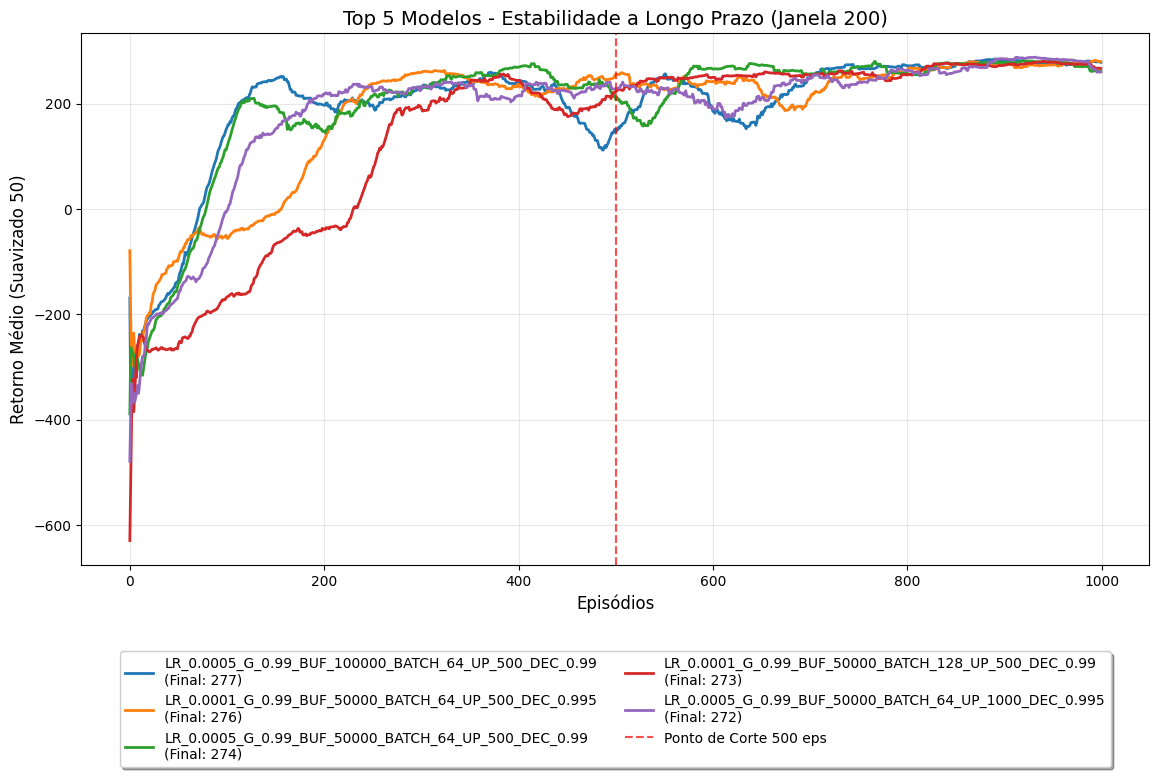


O melhor conjunto de hiperparâmetros é: LR_0.0005_G_0.99_BUF_100000_BATCH_64_UP_500_DEC_0.99


In [31]:
metrics_500 = {}
metrics_1000 = {}

WINDOW_SHORT = 100 
WINDOW_LONG = 200  
SMOOTHING_WINDOW = 50 

# --- Cálculo das Métricas ---
for name, data in results.items():
    scores = data["scores"]
    
    # Critério 1: Curto Prazo - 500 episodios
    if len(scores) >= 500:
        metrics_500[name] = np.mean(scores[500-WINDOW_SHORT:500])
    else:
        metrics_500[name] = -float('inf')
        
    # Critério 2: Longo Prazo - 1_000 episodios
    if len(scores) >= 1000:
        metrics_1000[name] = np.mean(scores[-WINDOW_LONG:])
    else:
        metrics_1000[name] = -float('inf')

# Top 5
top_short = sorted(metrics_500.items(), key=lambda x: x[1], reverse=True)[:5]
top_long = sorted(metrics_1000.items(), key=lambda x: x[1], reverse=True)[:5]

print("=== ANÁLISE DE TEMPO DE TREINAMENTO ===")
print(f"\nMelhores no Curto Prazo (Média dos eps {500-WINDOW_SHORT}-{500}):")
for rank, (name, score) in enumerate(top_short):
    print(f"#{rank+1}: {name} | Score: {score:.2f}")

print(f"\nMelhores no Longo Prazo (Média dos últimos {WINDOW_LONG} eps):")
for rank, (name, score) in enumerate(top_long):
    print(f"#{rank+1}: {name} | Score: {score:.2f}")

# --- PLOTAGEM ---
plt.figure(figsize=(12, 8)) 

for name, score in top_long:
    scores = results[name]["scores"]
    smoothed = pd.Series(scores).rolling(window=SMOOTHING_WINDOW, min_periods=1).mean()
    plt.plot(smoothed, label=f"{name}\n(Final: {score:.0f})", linewidth=2)

plt.axvline(x=500, color='r', linestyle='--', label="Ponto de Corte 500 eps", alpha=0.7)
plt.title(f"Top 5 Modelos - Estabilidade a Longo Prazo (Janela {WINDOW_LONG})", fontsize=14)
plt.xlabel("Episódios", fontsize=12)
plt.ylabel(f"Retorno Médio (Suavizado {SMOOTHING_WINDOW})", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fancybox=True, shadow=True)

plt.tight_layout()
plt.show()

best_model_name = top_long[0][0]
print(f"\nO melhor conjunto de hiperparâmetros é: {best_model_name}")

## Comparação Stable Baselines3

In [50]:
# --- Configuração do Callback para Coletar Dados do SB3 ---
class EpisodeInfoCallback(BaseCallback):
    def __init__(self, verbose=0):
        super(EpisodeInfoCallback, self).__init__(verbose)
        self.episode_rewards = []
        self.current_episode_reward = 0

    def _on_step(self) -> bool:
        # Soma a recompensa do passo atual
        self.current_episode_reward += self.locals['rewards'][0]
        
        # Verifica se o episódio acabou
        if self.locals['dones'][0]:
            self.episode_rewards.append(self.current_episode_reward)
            self.current_episode_reward = 0
        return True

In [51]:
# Callback 1: Para parar quando chegar em 1000 episódios
stop_callback = StopTrainingOnMaxEpisodes(max_episodes=1000, verbose=1)

# Callback 2: O callback para guardar os scores
info_callback = EpisodeInfoCallback()


callback_list = CallbackList([stop_callback, info_callback])

In [52]:
# --- Treinamento ---
print("--- Iniciando Treinamento com SB3 (Limite: 1000 Episódios) ---")

env_sb3 = gym.make("LunarLander-v3", continuous=False)
model_sb3 = DQN("MlpPolicy", env_sb3, verbose=0, seed=SEED)

# O 'stop_callback' vai interromper o treino muito antes do limite de 10_000_000 passos, ao atingir 1_000 episodios.
model_sb3.learn(total_timesteps=10_000_000, callback=callback_list)


sb3_scores = info_callback.episode_rewards

--- Iniciando Treinamento com SB3 (Limite: 1000 Episódios) ---
Stopping training with a total of 96136 steps because the DQN model reached max_episodes=1000, by playing for 1000 episodes 


In [56]:
# --- Dados do melhor modelo implementado anteriormente ---
if 'results' in locals() and best_model_name in results:
    my_best_scores = results[best_model_name]['scores']
else:
    print("ERRO: Os resultados do modelo não foram encontrados. Rode a célula de carga de arquivo primeiro!")
    my_best_scores = [] # Evita crash

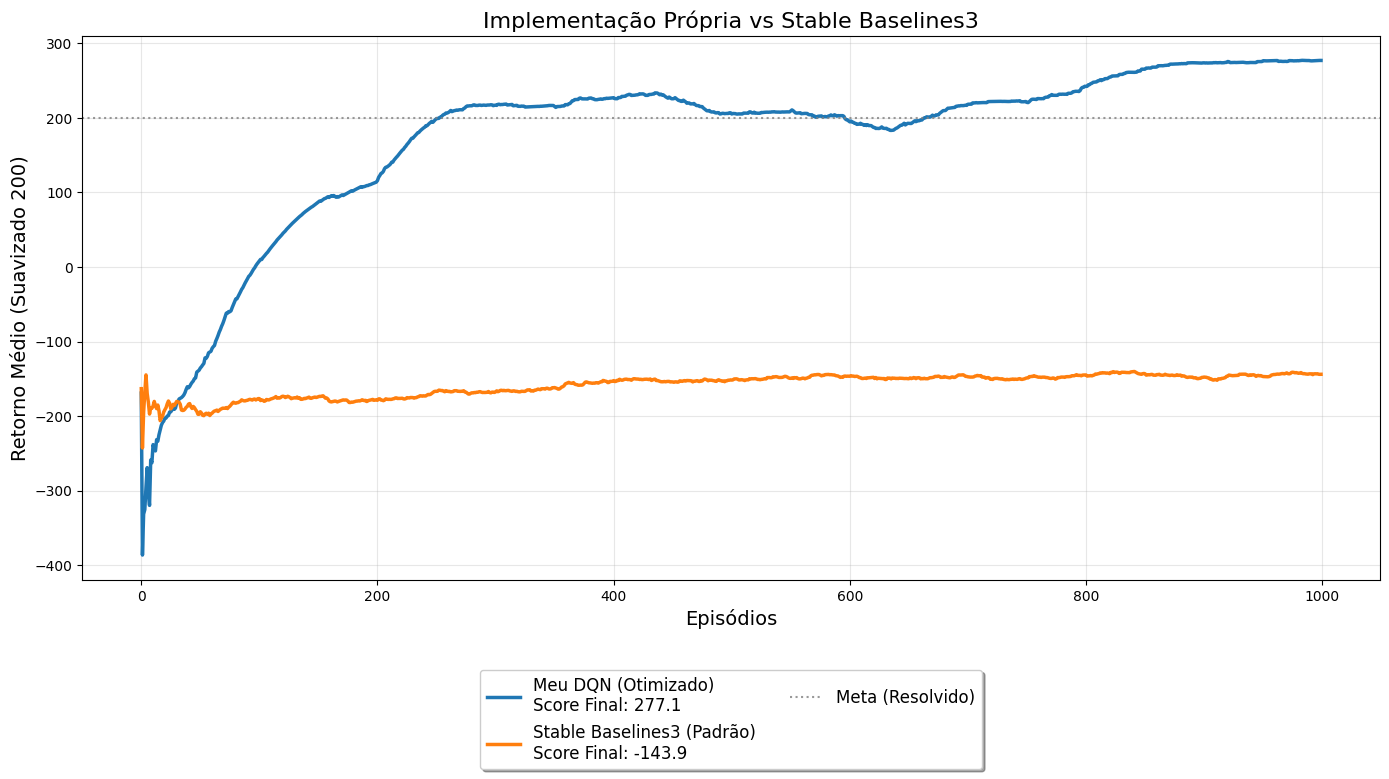

In [57]:
# --- Plotagem Comparativa ---
plt.figure(figsize=(14, 8))

min_len = min(len(my_best_scores), len(sb3_scores))
my_data = my_best_scores[:min_len]
sb3_data = sb3_scores[:min_len]

# Suavização 
WINDOW = 200
my_smooth = pd.Series(my_data).rolling(window=WINDOW, min_periods=1).mean()
sb3_smooth = pd.Series(sb3_data).rolling(window=WINDOW, min_periods=1).mean()

# Plot
plt.plot(my_smooth, label=f"Meu DQN (Otimizado)\nScore Final: {my_smooth.iloc[-1]:.1f}", linewidth=2.5)
plt.plot(sb3_smooth, label=f"Stable Baselines3 (Padrão)\nScore Final: {sb3_smooth.iloc[-1]:.1f}", linewidth=2.5)

# Linha de meta
plt.axhline(y=200, color='grey', linestyle=':', alpha=0.8, label="Meta (Resolvido)")

plt.title("Implementação Própria vs Stable Baselines3", fontsize=16)
plt.xlabel("Episódios", fontsize=14)
plt.ylabel(f"Retorno Médio (Suavizado {WINDOW})", fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, fancybox=True, shadow=True, fontsize=12)

plt.tight_layout()
plt.show()

In [60]:
# --- Tabela de Resultados ---
print("\n" + "="*45)
print(f"{'MÉTRICA':<20} | {'MEU DQN':<10} | {'SB3':<10}")
print("-" * 45)
print(f"{'Média Final':<20} | {my_smooth.iloc[-1]:<10.1f} | {sb3_smooth.iloc[-1]:<10.1f}")
print(f"{'Máximo Score':<20} | {np.max(my_data):<10.1f} | {np.max(sb3_data):<10.1f}")
print("="*45)


MÉTRICA              | MEU DQN    | SB3       
---------------------------------------------
Média Final          | 277.1      | -143.9    
Máximo Score         | 322.5      | 74.8      


## Conclusão

O trabalho atingiu os objetivos propostos, resultando na implementação de um agente Deep Q-Network (DQN) capaz de solucionar o ambiente LunarLander-v3. A solução desenvolvida, utilizando PyTorch convergiu para uma política ótima, e demonstrou estabilidade e robustez ao lidar com o espaço de estados contínuo e a física do ambiente.

Os resultados experimentais evidenciaram que o sucesso do DQN é fortemente dependente da seleção dos hiperparâmetros. A busca sistemática revelou que um buffer de repetição maior (100.000 transições) e uma taxa de aprendizado moderada (5e-4) foram responsáveis pela estabilidade do aprendizado. Com essa configuração, o agente alcançou uma recompensa média de 277.1 nos últimos episódios, superando com folga o critério de 200 pontos que define o ambiente como resolvido.

A análise comparativa destacou uma diferença significativa de desempenho em relação à implementação padrão da biblioteca Stable Baselines3 (SB3). Enquanto a solução própria convergiu rapidamente, o agente SB3 falhou em aprender a tarefa dentro dos 1.000 episódios disponíveis. Foi identificado que isso ocorreu por conta da configuração conservadora de aquecimento (warm-up) do SB3, mostrando que algoritmos de Aprendizado por Reforço Profundo exigem adaptação específica para cada domínio, e que soluções genéricas podem não ser eficazes em cenários com restrição de tempo de treinamento.

**Trabalhos Futuros e Melhorias**

Para aprimoramentos futuros e continuidade deste trabalho, as seguintes direções podem ser tomadas:

*	Variações do Algoritmo: Implementar melhorias conhecidas do DQN, como Double DQN (para reduzir a superestimação dos valores Q) e Dueling DQN (para separar a estimativa de valor do estado da vantagem da ação), avaliando se trazem ganhos de estabilidade ou eficiência.
*	Prioritized Experience Replay: Substituir a amostragem uniforme do buffer de replay por uma amostragem priorizada, focando nas transições onde o agente cometeu maiores erros de predição (maior erro TD), o que teoricamente acelera a convergência.
*	Ajuste Fino do SB3: Realizar uma busca de hiperparâmetros também para o agente do Stable Baselines3, permitindo uma comparação mais justa entre a melhor versão de ambas as implementações.
*	Generalização: Testar a robustez do agente treinado em variações do ambiente, como alterações na gravidade ou turbulência de vento, para avaliar a capacidade de generalização da política aprendida.
*	Busca de hiperparâmetros: Expandir a busca de hiperparâmetros no DQN implementado, utilizando mais variações para cada parâmetro. Importante ter tempo e recurso disponível, as configurações atuais gastaram aproximadamente 3 dias e meio para rodar as 96 simulações.
